In [ ]:

# Import Required Libraries

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
# Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Read the dataset from Google Drive

df = pd.read_csv('/content/drive/MyDrive/kushal/StudentPerformanceFactors.csv')

In [ ]:

df_original = df.copy()

In [ ]:
# Display the first five rows

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
df. shape

(6607, 20)

In [ ]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

In [ ]:
df. info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [ ]:
# Check missing values

df.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


In [ ]:
categorical_columns = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
df.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


In [ ]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [ ]:
df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [ ]:
# Display 5 random students

df.sample(5, random_state=42)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
743,20,71,Medium,Low,No,7,87,High,Yes,1,Medium,Medium,Public,Negative,5,No,High School,Near,Male,65
5551,22,71,Medium,Low,Yes,7,98,Low,Yes,2,Low,High,Public,Neutral,2,No,High School,Moderate,Female,65
3442,21,91,High,Medium,Yes,6,53,High,Yes,1,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Female,71
6571,12,91,Medium,Low,Yes,8,81,Low,Yes,0,Low,Low,Public,Positive,4,No,High School,Moderate,Male,64
4204,21,63,Low,High,Yes,8,95,Medium,Yes,2,High,Medium,Public,Neutral,5,No,High School,Near,Male,66


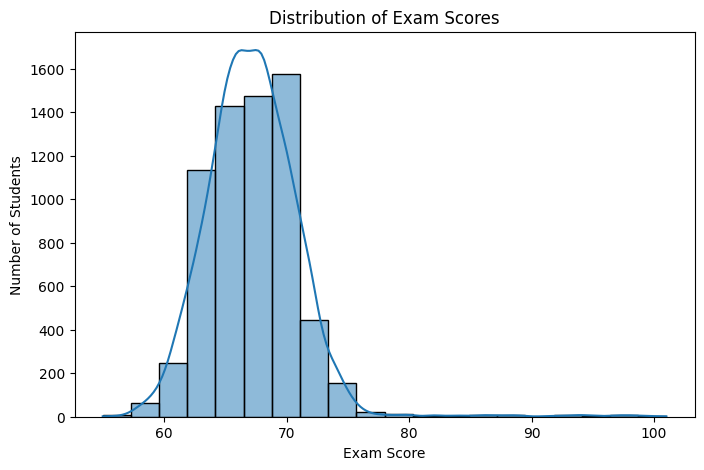

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Exam_Score"], bins=20, kde=True)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

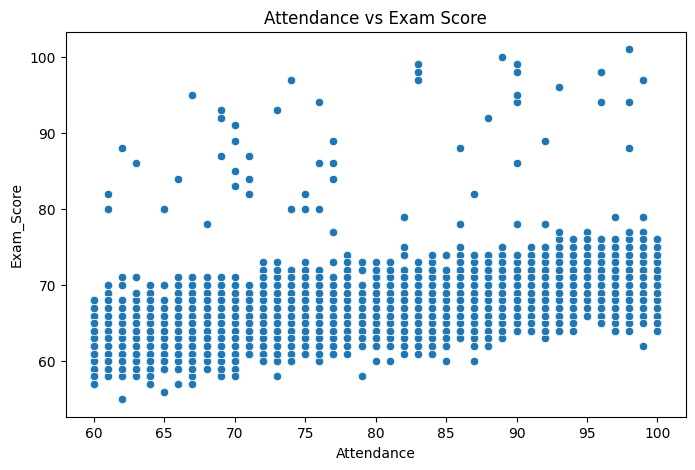

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="Attendance",
    y="Exam_Score",
    data=df
)

plt.title("Attendance vs Exam Score")

plt.show()

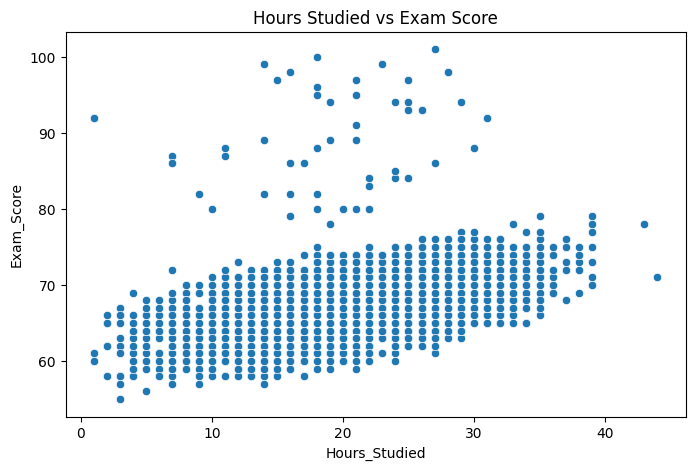

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="Hours_Studied",
    y="Exam_Score",
    data=df
)

plt.title("Hours Studied vs Exam Score")

plt.show()

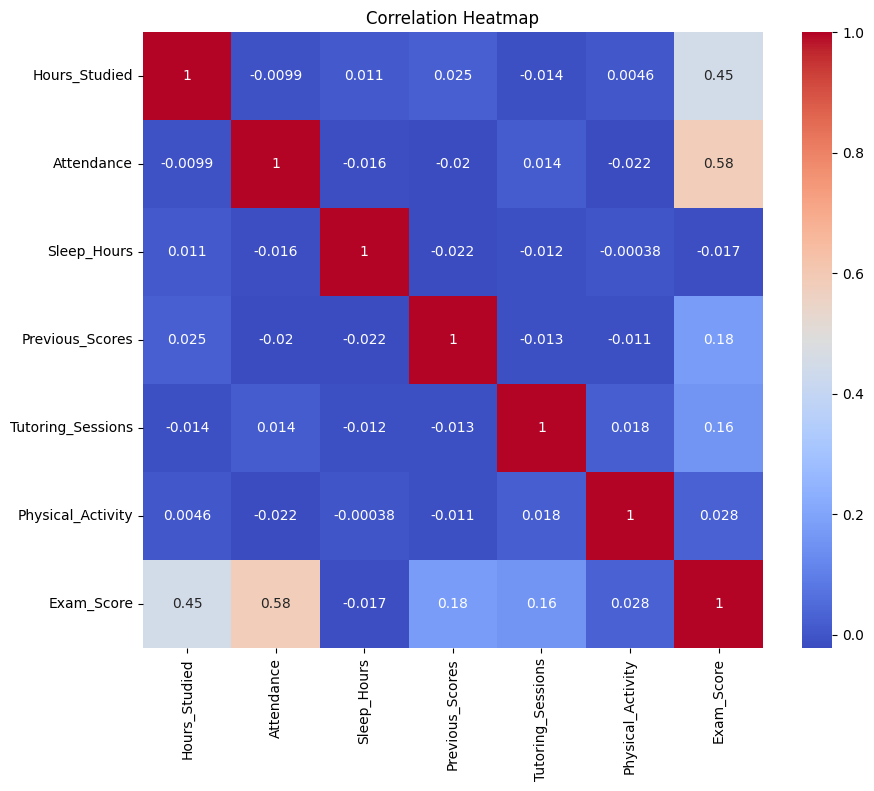

In [ ]:
plt.figure(figsize=(10,8))

corr = df.select_dtypes(include=["number"]).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

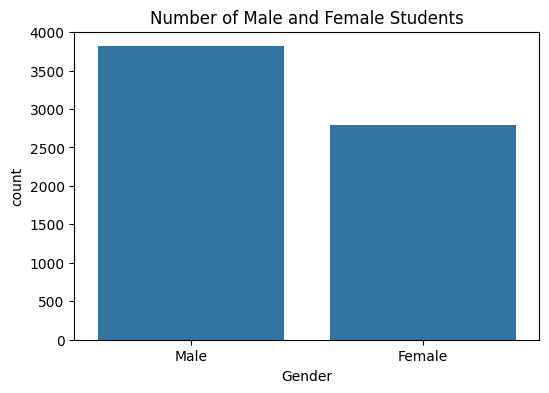

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Gender",
    data=df
)

plt.title("Number of Male and Female Students")

plt.show()

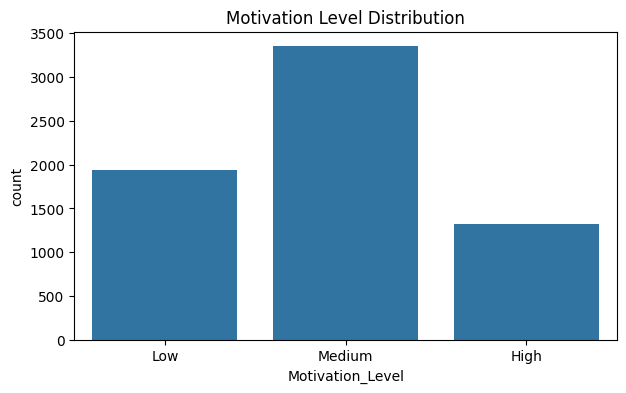

In [ ]:
plt.figure(figsize=(7,4))

sns.countplot(
    x="Motivation_Level",
    data=df
)

plt.title("Motivation Level Distribution")

plt.show()

In [ ]:
import pandas as pd

# Divide students into 3 equal groups based on Exam_Score
df["Performance"] = pd.qcut(
    df["Exam_Score"],
    q=3,
    labels=["Poor", "Average", "Excellent"]
)

# Check the distribution
print(df["Performance"].value_counts())

Performance
Poor         2882
Average      2100
Excellent    1625
Name: count, dtype: int64


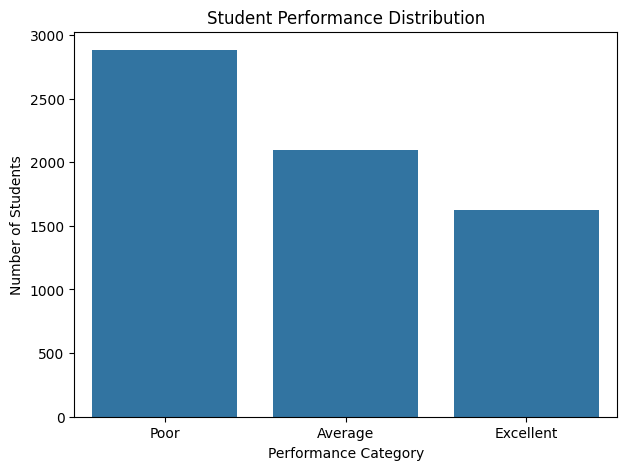

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="Performance",
    data=df,
    order=["Poor","Average","Excellent"]
)

plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()

In [ ]:

# Encode Target Variable


performance_encoder = LabelEncoder()

df["Performance"] = performance_encoder.fit_transform(df["Performance"])

print(df["Performance"].value_counts())

Performance
2    2882
0    2100
1    1625
Name: count, dtype: int64


In [ ]:

# Encode Categorical Features


feature_encoders = {}

categorical_columns = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns)

for column in categorical_columns:

    encoder = LabelEncoder()

    df[column] = encoder.fit_transform(df[column])

    feature_encoders[column] = encoder

Categorical Columns:
Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')


In [ ]:

# Separate Features and Target


X = df.drop(columns=["Exam_Score", "Performance"])

y = df["Performance"]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (6607, 19)
Target Shape : (6607,)


In [ ]:

# Feature Importance using Random Forest


rf = RandomForestClassifier(random_state=42)

rf.fit(X, y)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
1,Attendance,0.311563
0,Hours_Studied,0.186468
6,Previous_Scores,0.091669
9,Tutoring_Sessions,0.045375
5,Sleep_Hours,0.043055
14,Physical_Activity,0.036502
3,Access_to_Resources,0.034183
2,Parental_Involvement,0.030191
13,Peer_Influence,0.028467
16,Parental_Education_Level,0.027017


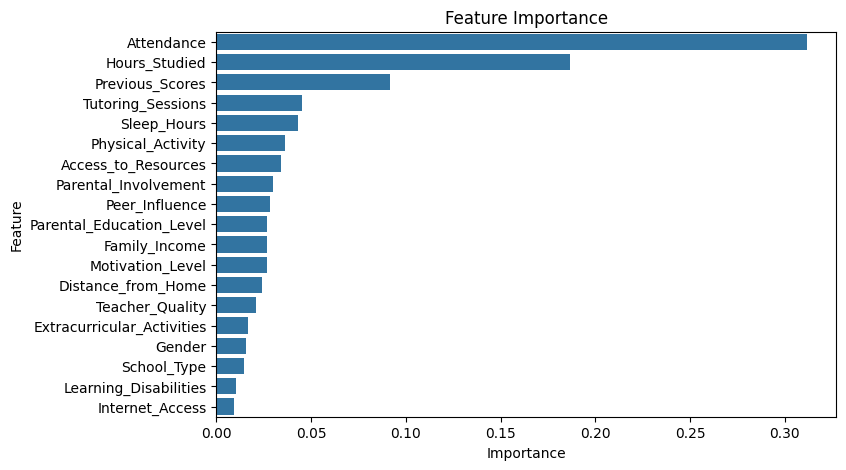

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

In [ ]:
# Select only the important features

X = df[
    [
        "Attendance",
        "Hours_Studied",
        "Previous_Scores",
        "Tutoring_Sessions",
        "Sleep_Hours",
        "Physical_Activity",
        "Access_to_Resources",
        "Parental_Involvement"
    ]
]

# Target
y = df["Performance"]

In [ ]:

# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape :", X_train.shape)
print("Testing Data Shape  :", X_test.shape)

Training Data Shape : (5285, 8)
Testing Data Shape  : (1322, 8)


In [ ]:

# Feature Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully")

Feature Scaling Completed Successfully


In [ ]:

# Train Initial KNN Model

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

print("Initial KNN Model Trained")

Initial KNN Model Trained


In [ ]:

# Predict Test Data

y_pred = knn.predict(X_test)

In [ ]:

# Initial Model Evaluation

accuracy = accuracy_score(y_test, y_pred)

print(f"Initial Accuracy : {accuracy:.4f}")

Initial Accuracy : 0.7640


In [ ]:

# Classification Report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Poor","Average","Excellent"]
))

              precision    recall  f1-score   support

        Poor       0.63      0.68      0.65       420
     Average       0.76      0.75      0.75       325
   Excellent       0.88      0.84      0.86       577

    accuracy                           0.76      1322
   macro avg       0.76      0.75      0.75      1322
weighted avg       0.77      0.76      0.77      1322



In [ ]:

# Find the Best Value of K

accuracies = []

k_values = range(1,76)

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, prediction)

    accuracies.append(accuracy)

best_accuracy = max(accuracies)

best_k = accuracies.index(best_accuracy)+1

print("Best K :", best_k)

print("Best Accuracy :", best_accuracy)

Best K : 40
Best Accuracy : 0.783661119515885


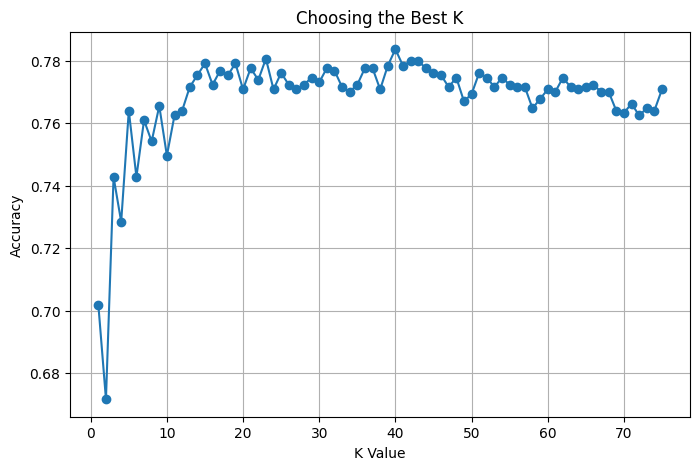

In [ ]:

# Accuracy for Different K Values

plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    accuracies,
    marker="o"
)

plt.xlabel("K Value")

plt.ylabel("Accuracy")

plt.title("Choosing the Best K")

plt.grid(True)

plt.show()

In [ ]:

# Final KNN Model

knn = KNeighborsClassifier(
    n_neighbors=best_k
)

knn.fit(
    X_train,
    y_train
)

y_pred = knn.predict(
    X_test
)

In [ ]:

# Final Accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Final Accuracy : {accuracy:.4f}")

Final Accuracy : 0.7837


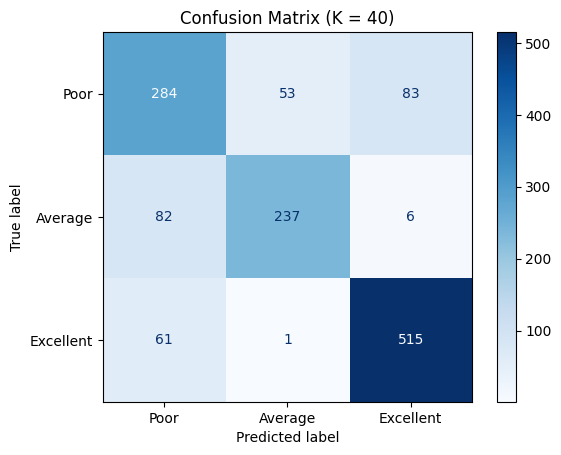

In [ ]:

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=["Poor","Average","Excellent"]

)

disp.plot(cmap="Blues")

plt.title(f"Confusion Matrix (K = {best_k})")

plt.show()

In [ ]:

# Final Classification Report

print(classification_report(

    y_test,

    y_pred,

    target_names=["Poor","Average","Excellent"]

))

              precision    recall  f1-score   support

        Poor       0.67      0.68      0.67       420
     Average       0.81      0.73      0.77       325
   Excellent       0.85      0.89      0.87       577

    accuracy                           0.78      1322
   macro avg       0.78      0.77      0.77      1322
weighted avg       0.78      0.78      0.78      1322



In [ ]:

# Predict Performance of a New Student

new_student = {

    "Attendance": 90,

    "Hours_Studied": 15,

    "Previous_Scores": 82,

    "Tutoring_Sessions": 3,

    "Sleep_Hours": 7,

    "Physical_Activity": 4,

    "Access_to_Resources": "High",

    "Parental_Involvement": "Medium"

}

In [ ]:

# Encode User Input


new_student["Access_to_Resources"] = feature_encoders["Access_to_Resources"].transform(
    [new_student["Access_to_Resources"]]
)[0]

new_student["Parental_Involvement"] = feature_encoders["Parental_Involvement"].transform(
    [new_student["Parental_Involvement"]]
)[0]

In [ ]:

# Convert User Input to DataFrame

new_df = pd.DataFrame([new_student])

new_df

,Attendance,Hours_Studied,Previous_Scores,Tutoring_Sessions,Sleep_Hours,Physical_Activity,Access_to_Resources,Parental_Involvement
0,90,15,82,3,7,4,0,2


In [ ]:

# Scale Input

new_scaled = scaler.transform(new_df)

In [ ]:

# Predict Student Performance

prediction = knn.predict(new_scaled)

In [ ]:

# Decode Prediction

result = performance_encoder.inverse_transform(prediction)

print("=" * 45)
print("Predicted Student Performance")
print("=" * 45)

print("Prediction :", result[0])

print(f"\nModel Accuracy : {accuracy*100:.2f}%")

Predicted Student Performance
Prediction : Average

Model Accuracy : 78.37%
